# 2 근거·상태·승인을 갖춘 Agent 만들기

오늘은 문서에서 근거를 찾고, 상태를 저장하며, 사람의 승인에 따라 실행 경로를 나눕니다. 마지막에는 질문과 근거를 함께 보여 주는 Streamlit 화면으로 연결합니다. 실습 자료는 AI Agent 개념을 담은 교육용 문서이며 실제 사내 문서가 아닙니다.

**사용 방법:** 위에서부터 셀을 실행합니다. 기본은 외부 API 없이 동작하는 실습입니다. `[모의]`는 고정 응답 또는 교육용 자료이며 실제 모델 품질을 뜻하지 않습니다. `RUN_LIVE=True`는 환경 파일을 확인한 뒤 실제 모델을 연결할 때만 선택합니다. 그림은 이 노트북 안에 포함되어 있습니다.

**실습 방식:** 결과를 예상하고 실행한 뒤, CodeMate에 목표·입출력·제약·검증 기준을 전달하세요. 수정 결과를 직접 확인하고 다시 지시합니다.


In [ ]:
from pathlib import Path
import sys, os
import importlib.metadata as package_version

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/courseware").is_dir()), None)
if ROOT is None:
    raise RuntimeError("프로젝트 안에서 노트북을 열어 주세요.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RUN_LIVE = False
ENABLE_LANGFUSE = False
if RUN_LIVE:
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env", override=False)
else:
    os.environ["LANGCHAIN_TRACING_V2"] = "false"
    os.environ["LANGSMITH_TRACING"] = "false"
print("실행 모드:", "실제 모델 연결" if RUN_LIVE else "모의 모델·교육용 자료")
print("Python", sys.version.split()[0])


## 2.1 RAG와 RAGaaS

**이 블록의 결과물:** 검색된 근거와 생성된 답변을 구별하고, 근거가 부족한 질문에 응답하는 흐름을 만듭니다.


### 2.1.1 모델에 지식을 넣는 두 가지 위치

RAG는 질문과 관련된 외부 자료를 찾아 **현재 모델 입력에 추가**합니다. 모델의 매개변수를 바꾸지 않고 참고 자료를 바꿀 수 있으므로 갱신되는 지식이나 문서 근거가 필요한 질문에 사용합니다. Fine-Tuning은 학습을 통해 모델의 행동을 조정합니다. 두 방법은 함께 사용할 수도 있습니다.

RAG를 붙였다는 사실만으로 답변이 정확해지지는 않습니다. 필요한 문서가 검색되지 않거나, 검색된 문서를 잘못 해석하면 답변이 틀릴 수 있습니다. 그래서 “찾았는가”와 “근거에 맞게 답했는가”를 따로 검토합니다.

수업에서는 문서 ID, 제목, 본문, 출처를 함께 유지합니다. 이후 답변의 출처가 실제 검색된 자료에 있는지 검사할 수 있도록 처음부터 정보를 버리지 않습니다.


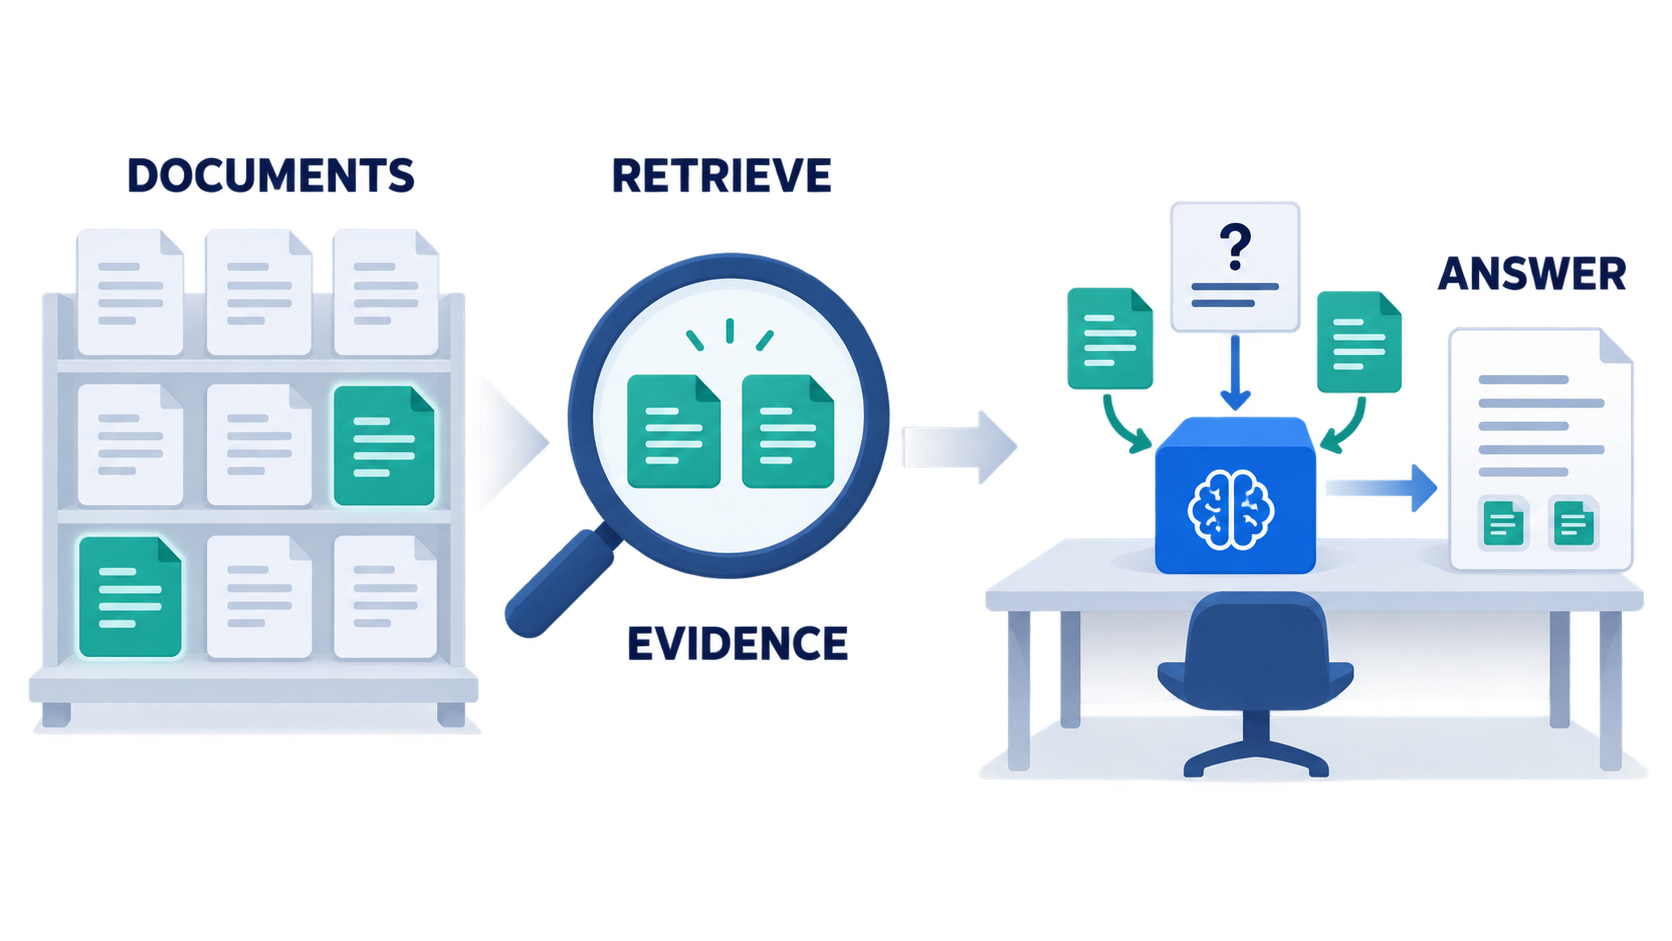

**그림 2.1.1.1 — 선택한 문서가 답변의 근거가 됩니다**

자료 모음에서 두 문서를 골라 질문과 함께 모델에 전달합니다. 답변의 작은 출처 표시는 어떤 문서를 썼는지 돌아볼 수 있게 합니다.

**보면서 확인:** 관련 없는 문서가 선택되면 어떤 단계부터 다시 확인할까요?

**표현 범위:** 문서 개수와 아이콘은 예시이며 이 삽화가 검색 품질을 보장하지 않습니다.


In [ ]:
from courseware.knowledge import load_documents, retrieve, answer_from_documents, KeywordEmbeddings
training_documents = load_documents()
print("교육용 문서 수:", len(training_documents))
for doc in retrieve("RAG 검색 근거", k=2):
    print(doc["id"], doc["title"], doc["source"])


**실행에서 볼 것**

여기서는 태그와 단어 겹침으로 문서를 검색합니다. 이 단계의 검색 점수는 학습된 의미 임베딩의 유사도가 아닙니다.


**CodeMate와 확인하기**

> 문서 목록에서 RAG 질문에 필요한 근거를 직접 고른 뒤 retrieve 결과와 비교해 주세요. 검색에 성공했지만 답변을 만들기에 부족한 질문도 하나 적어 주세요. 실제 회사 규정이나 최신 정보를 문서에 없는 상태로 만들어 넣지 마세요.


### 2.1.2 Loading·Splitting·Embedding

Loading은 자료를 읽어 본문과 메타데이터로 만드는 단계입니다. PDF에서는 파일명과 페이지, 웹에서는 URL과 수집 시점 등이 근거 추적에 도움이 됩니다. 텍스트가 추출되지 않는 이미지 PDF는 별도 처리가 필요할 수 있습니다.

Splitting은 긴 문서를 검색할 조각으로 나눕니다. 너무 작으면 조건과 예외가 갈라지고, 너무 크면 관련 없는 내용이 함께 들어갑니다. Recursive 분할은 문단·문장 등의 경계를 우선 시도합니다. 글자 수 기준 설정과 토큰 수 기준 설정을 혼동하지 마세요.

Embedding은 텍스트를 수치 벡터로 바꿉니다. 의미 임베딩은 학습된 모델이 의미 관계를 표현하도록 만든 것입니다. 아래 `KeywordEmbeddings`는 고정 단어의 출현 횟수만 담는 **설명용 벡터**입니다. 실제 임베딩 API를 검증한 것으로 해석하지 않습니다.


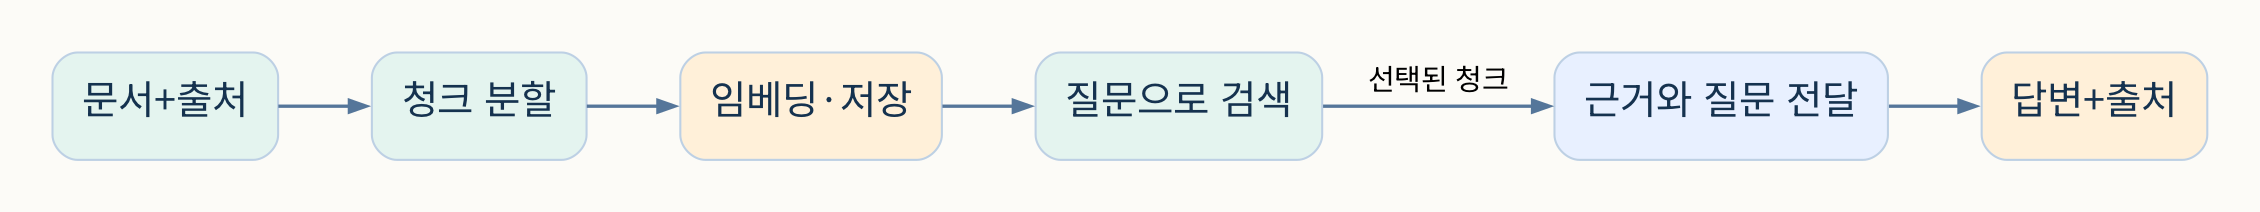

**그림 2.1.2.1 — 문서의 출처를 검색과 답변까지 전달합니다**

저장 전 문서 분할과 벡터화를 수행하고, 질문 때 관련 청크를 선택합니다. 답변에는 선택된 근거가 들어갑니다.

**보면서 확인:** 출처 메타데이터가 빠지면 어느 단계에서 문제가 드러날까요?

**표현 범위:** 질문 임베딩과 인덱스 세부 구현을 간략화한 흐름입니다.


In [ ]:
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
loaded = [Document(page_content=d["text"], metadata={"id": d["id"], "source": d["source"]}) for d in training_documents]
splitter = RecursiveCharacterTextSplitter(chunk_size=90, chunk_overlap=15, separators=["。", ". ", " ", ""])
chunks = splitter.split_documents(loaded)
embedding_model = KeywordEmbeddings()
if RUN_LIVE:
    from config.embeddings import get_embeddings
    embedding_model = get_embeddings()
vectors = embedding_model.embed_documents([doc.page_content for doc in chunks])
print("원문 / 청크:", len(loaded), len(chunks))
print("벡터 차원:", len(vectors[0]))
print("첫 청크 출처:", chunks[0].metadata)


**실행에서 볼 것**

청크가 나뉘어도 문서 ID와 출처가 남습니다. 모의 모드의 12차원은 단어 목록 12개에 대응하며 실제 서비스 모델의 차원이 아닙니다.


**CodeMate와 확인하기**

> chunk_size를 60과 120으로 바꾸어 청크 수와 문맥 보존을 비교해 주세요. 승인 조건과 거절 조건이 서로 다른 청크로 갈라지는지 확인하고, 검색 질문 하나를 기준으로 어떤 분할이 나은지 근거를 적어 주세요.


### 2.1.3 Storage·Retrieval·Generation

벡터 저장소는 벡터만 보관하는 곳이 아닙니다. 원문 조각과 메타데이터를 함께 관리해야 검색 뒤 내용을 읽고 출처를 표시할 수 있습니다. 새 임베딩 모델로 바꾸면 기존 인덱스와 호환되는지 확인하고 필요한 경우 다시 만들어야 합니다.

검색의 `k`는 가져올 후보 수입니다. 많은 후보가 항상 더 좋은 답변을 만들지는 않습니다. 관련 없는 자료가 늘면 입력 비용과 혼동이 함께 커질 수 있습니다. 거리나 점수의 의미는 저장소와 측정 방식에 따라 다릅니다.

아래는 **실제 Chroma 저장소**에 교육용 벡터를 넣습니다. 수업 재실행 때 데이터가 누적되지 않도록 매번 별도 컬렉션을 사용합니다. 검색된 후보를 그대로 진실로 받아들이지 않고 질문과 맞는지 읽은 뒤 답변을 구성합니다.


In [ ]:
import uuid
import chromadb
from chromadb.config import Settings
from langchain_chroma import Chroma
chroma_client = chromadb.EphemeralClient(settings=Settings(anonymized_telemetry=False))
vector_store = Chroma.from_documents(chunks, embedding_model, client=chroma_client, collection_name="lesson-" + uuid.uuid4().hex)
retrieved = vector_store.similarity_search("문서 검색 근거", k=2)
for doc in retrieved:
    print(doc.metadata["id"], doc.page_content)
context_text = "\n".join(f'[{doc.metadata["id"]}] {doc.page_content}' for doc in retrieved)
print("모델에 전달할 근거:\n", context_text)


**실행에서 볼 것**

검색 단계는 실제 저장소에서 실행됩니다. 모의 벡터는 단어가 겹치는 문서를 찾는 실험이며 실제 의미 검색 성능과 다릅니다. 메모리 컬렉션이므로 프로세스가 끝나면 유지되지 않습니다.


**CodeMate와 확인하기**

> 검색 후보 k=1과 k=3을 비교해 주세요. 후보마다 질문에 답하는 문장이 있는지 표시하고, “검색 결과가 존재함”과 “답할 근거가 충분함”을 구분하는 조건을 제안하세요. 장기 보관을 추가한다면 별도 persist_directory와 모델 식별 정보를 함께 관리하세요.


### 2.1.4 사내 RAGaaS와 사외 모의 응답

RAGaaS는 검색·저장 기능 일부를 서비스 API로 제공합니다. 수업 코드는 요청 JSON을 만들고 인증 헤더와 함께 전송한 뒤 응답에서 문서 내용을 읽습니다. 서비스가 맡는 기능과 애플리케이션이 맡는 답변 생성·출처 확인을 구분하세요.

이 저장소는 `post_ragaas()`로 사내 요청과 사외 모의 응답을 선택합니다. 사내 요청에는 게이트웨이 인증과 `api-key` 헤더가 필요합니다. 실제 설정은 환경 파일에만 두고 화면에 출력하지 않습니다.

아래 모의 응답은 요청·응답 형태를 확인하는 자료입니다. 질문 문구가 응답에 포함되어도 실제 문서를 검색했다는 뜻이 아닙니다. 요청은 원본 실습 `src/raw/Chapter01/03-rag/05_ragaas.py`와 같습니다. 사내에서 `RUN_LIVE=True`, `RAG_PROVIDER=samsung`으로 실행하면 같은 요청이 펫보험 약관 인덱스를 실제로 검색합니다.


In [ ]:
from unittest.mock import patch
from config.ragaas import post_ragaas
# 원본 실습(05_ragaas.py)과 같은 검색 요청
payload = {
    "index_name": "rp-aicoa-meritz-pet",
    "permission_groups": ["rag-public"],
    "query_text": "펫보험 보장 내용이 뭐야?",
    "num_result_doc": 3,
    "fields_exclude": ["v_merge_title_content"],
}
rag_mode = os.getenv("RAG_PROVIDER", "samsung") if RUN_LIVE else "mock"
with patch.dict(os.environ, {"RAG_PROVIDER": rag_mode}):
    rag_response = post_ragaas("retrieve-rrf", payload)
hits = rag_response.json()["hits"]["hits"]
print("RAGaaS 모드:", rag_mode, "/ 검색 결과 수:", len(hits))
print(hits[0]["_source"]["merge_title_content"][:300])
if rag_mode == "mock":
    assert "[MOCK RAGaaS]" in hits[0]["_source"]["merge_title_content"]


**실행에서 볼 것**

기본 실행은 모의 응답의 형식을 확인합니다. 사내 실제 연결에서는 결과 수와 첫 문서가 펫보험 약관 내용인지 확인합니다.


**CodeMate와 확인하기**

> src/raw/Chapter01/03-rag/05_ragaas.py와 config/ragaas.py를 읽고 검색 요청 필드, 두 인증 헤더, 응답 본문 추출 위치를 설명해 주세요. 사외에서는 mock을 유지하세요. 빈 hits와 잘못된 응답 구조를 각각 검출하는 함수를 만들어 주세요.


### 2.1.5 근거 없는 질문과 검색 평가

RAG의 가장 중요한 실패 사례는 **자료에 답이 없는 질문**입니다. 검색기는 항상 가까운 후보를 내놓을 수 있으므로 “후보가 나왔다”를 “답을 안다”로 바꾸면 안 됩니다. 알려진 답변과 알 수 없는 질문을 함께 준비해야 합니다.

검색 평가는 기대 문서가 결과에 있는지 확인하고, 답변 평가는 그 근거가 실제 주장과 맞는지 봅니다. 먼저 작은 질의셋으로 실패를 재현한 뒤 청킹, 질의 재작성, 혼합 검색, 재정렬 중 어느 부분을 고칠지 결정합니다.

아래 단어 검색은 관련 태그가 없으면 빈 목록을 반환합니다. 의미 검색에도 똑같이 적용할 만능 기준은 아닙니다. 수업용으로 “근거 없음” 경로를 명확히 재현하는 예입니다.


In [ ]:
questions = [
    ("RAG 검색 근거", "D1"),
    ("MCP 도구 연결", "D2"),
    ("교육장 휴게실 위치", None),
]
for question, expected in questions:
    result = answer_from_documents(question)
    ids = [d["id"] for d in result["sources"]]
    passed = expected in ids if expected else not ids
    print(question, ids, "통과" if passed else "검토 필요")
    if not ids:
        print(result["answer"])


**실행에서 볼 것**

답이 없는 질문은 자료에서 확인할 수 없다고 반환합니다. 추가 질문을 넣었을 때 예상과 다른 검색 결과가 나오는 사례를 보존하세요.


**CodeMate와 확인하기**

> 질의셋을 정상 3개, 근거 없음 2개, 표현이 다른 유사 질문 2개로 늘려 주세요. 기대 문서 ID와 실제 결과를 표로 비교하고 실패 원인을 한 단계에 연결해 주세요. 단순히 모든 문서를 반환해 점수를 높이지 마세요.


## 2.2 LangGraph의 상태와 분기

**이 블록의 결과물:** Node·Edge·State·Reducer를 읽고, 사람의 승인에 따라 실제 실행 경로가 달라지게 만듭니다.


### 2.2.1 선형 체인에서 상태가 있는 그래프로

한 번 검색하고 한 번 답하는 흐름은 선형 체인으로 표현할 수 있습니다. 검색이 부족하면 다시 검색하고, 사용자의 승인에 따라 다른 노드로 가야 한다면 흐름을 그래프로 표현하는 편이 읽기 쉽습니다.

LangGraph는 노드와 연결뿐 아니라 **실행 중 상태**를 다룹니다. 모델을 쓰지 않는 노드도 만들 수 있습니다. 따라서 그래프를 썼다는 이유만으로 자율 Agent가 되는 것은 아닙니다. 어떤 노드에서 모델이 선택하고 어떤 분기는 규칙으로 정하는지 표시해야 합니다.

먼저 작은 그래프가 질문을 받아 답변 필드를 채우는 과정을 실행합니다. 입력 상태 전체를 새로 만들기보다 노드가 바꿀 필드만 반환하는 방식에 주목하세요.


In [ ]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
class QAState(TypedDict, total=False):
    question: str
    answer: str

def respond(state: QAState):
    return {"answer": answer_from_documents(state["question"])["answer"]}

builder = StateGraph(QAState)
builder.add_node("respond", respond)
builder.add_edge(START, "respond")
builder.add_edge("respond", END)
qa_graph = builder.compile()
print(qa_graph.invoke({"question": "RAG 검색"}))


**실행에서 볼 것**

question은 입력에서 유지되고 answer는 노드가 추가합니다. 이 노드는 문서 발췌를 수행하는 규칙 기반 함수입니다.


**CodeMate와 확인하기**

> 위 그래프에 질문 공백을 정리하는 prepare 노드를 추가해 주세요. prepare→respond 순서가 되게 연결하고 빈 질문은 모델 호출 없이 안내하도록 바꾸세요. 변경 전후 State를 비교해 주세요.


### 2.2.2 Node·Edge·State와 Reducer

Node는 일을 수행하는 함수, Edge는 다음 실행 위치, State는 함수 사이에 전달되는 공유 자료입니다. State의 필드 이름과 타입이 명확하면 노드의 입력·출력 계약을 읽기 쉽습니다.

같은 필드를 여러 번 갱신할 때 합치는 규칙을 Reducer라고 부릅니다. 기본 덮어쓰기는 최신 값만 남깁니다. `operator.add`를 목록에 적용하면 새 항목을 붙입니다. 메시지는 같은 ID의 갱신도 다뤄야 하므로 LangGraph의 `add_messages` 같은 전용 규칙을 사용할 수 있습니다.

`TypedDict`는 구조를 설명하는 타입 표기이며 모든 값의 의미를 자동 검증하지 않습니다. 실행 입력의 엄격한 검사가 필요하면 Pydantic이나 별도 검증을 함께 사용합니다.


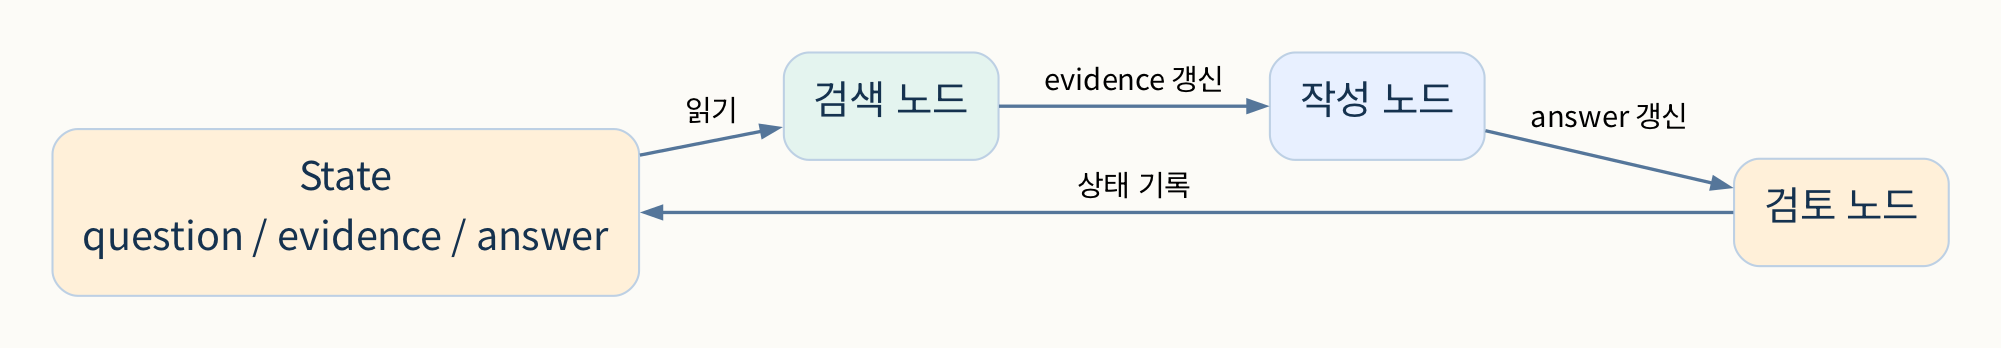

**그림 2.2.2.1 — 노드는 상태를 읽고 바뀐 부분을 반환합니다**

검색은 evidence, 작성은 answer, 검토는 확인 결과를 갱신합니다. 그래프의 연결은 이 갱신이 일어나는 순서를 정합니다.

**보면서 확인:** State와 노드를 각각 종이 메모와 작업자로 비유해 설명해 보세요.

**표현 범위:** 도식의 기록 화살표는 무한 반복을 지시하지 않습니다. 실제 Edge는 코드에서 확인합니다.


In [ ]:
import operator
class WorkState(TypedDict, total=False):
    question: str
    evidence: list[dict]
    events: Annotated[list[str], operator.add]

def search_node(state):
    return {"evidence": retrieve(state["question"]), "events": ["search"]}
def inspect_node(state):
    return {"events": ["has-evidence" if state["evidence"] else "no-evidence"]}

flow = StateGraph(WorkState)
flow.add_node("search", search_node)
flow.add_node("inspect", inspect_node)
flow.add_edge(START, "search")
flow.add_edge("search", "inspect")
flow.add_edge("inspect", END)
work_graph = flow.compile()
work_result = work_graph.invoke({"question": "MCP 도구", "events": []})
print(work_result["events"])


**실행에서 볼 것**

events에 search와 has-evidence가 함께 남습니다. 단순 list 필드로 바꾸면 마지막 갱신만 남을 수 있습니다.


**CodeMate와 확인하기**

> events 필드에서 Reducer가 있을 때와 없을 때 결과를 비교해 주세요. 목록 전체를 매번 반환하면서 add로 합치면 중복이 생기는 사례도 보여 주세요. 각 노드는 새 이벤트만 반환하도록 수정하세요.


### 2.2.3 도구 호출 뒤 모델로 돌아오기

도구를 쓰는 그래프에서 모델 노드는 도구 호출을 포함한 AIMessage를 만들 수 있습니다. `ToolNode`는 지정된 도구를 실행하고 ToolMessage를 반환합니다. `tools_condition`은 도구 요청이 있는지 보고 도구 노드 또는 종료로 보냅니다.

도구 노드 뒤에 모델로 돌아가는 연결이 있어야 모델이 실행 결과를 보고 답할 수 있습니다. 연결을 빼면 도구만 실행하고 사용자에게 답하지 못할 수 있습니다. 반대로 종료 조건 없이 되돌아가면 반복 한도에 걸릴 수 있습니다.

아래는 같은 multiply 도구를 직접 LangGraph로 연결합니다. 1일차의 create_agent와 비교해 어떤 반복 구조가 들어 있었는지 읽습니다.


In [ ]:
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from courseware.models import ScriptedMultiplyModel
@tool
def multiply(a: int, b: int) -> int:
    """두 정수를 곱한다."""
    return a * b
class MessageState(TypedDict):
    messages: Annotated[list, add_messages]
if RUN_LIVE:
    from config.llm import get_llm
    graph_model = get_llm().bind_tools([multiply])
else:
    graph_model = ScriptedMultiplyModel().bind_tools([multiply])
def model_node(state):
    return {"messages": [graph_model.invoke(state["messages"])]}
tool_builder = StateGraph(MessageState)
tool_builder.add_node("model", model_node)
tool_builder.add_node("tools", ToolNode([multiply]))
tool_builder.add_edge(START, "model")
tool_builder.add_conditional_edges("model", tools_condition)
tool_builder.add_edge("tools", "model")
tool_graph = tool_builder.compile()
result = tool_graph.invoke({"messages": [HumanMessage(content="8과 9를 곱해줘")]}, config={"recursion_limit": 8})
print([(m.type, m.content) for m in result["messages"]])


**실행에서 볼 것**

ToolMessage의 72가 다음 모델 호출에 전달됩니다. recursion_limit은 그래프 실행 한도이며 업무 완료 기준과 같지 않습니다.


**CodeMate와 확인하기**

> tools→model 연결이 왜 필요한지 메시지 목록으로 설명해 주세요. 숫자가 부족한 질문에서는 도구를 호출하지 않고 종료되는지 확인하세요. 반복 제한을 지나치게 작게 설정했을 때의 오류를 성공 답변으로 바꾸지 마세요.


### 2.2.4 사람의 승인으로 멈추고 재개하기

`interrupt()`는 그래프를 멈추고 사람에게 확인할 자료를 돌려줍니다. 재개할 때는 같은 thread_id와 `Command(resume=...)`를 사용합니다. 이를 위해 Checkpointer를 연결해야 합니다.

재개 시 중단된 노드의 함수는 처음부터 다시 실행될 수 있습니다. 따라서 중단 전에는 실제 발송·결제 같은 되돌리기 어려운 행동을 두지 않습니다. 승인 결과를 상태에 기록한 다음 별도 실행 노드로 이동하도록 나누면 경계가 분명합니다.

이 실습의 “작성”은 메모리에 문자열을 만드는 동작입니다. 외부 메일을 발송하지 않습니다. True와 False가 실제로 서로 다른 노드 경로로 이어지는지 확인합니다.


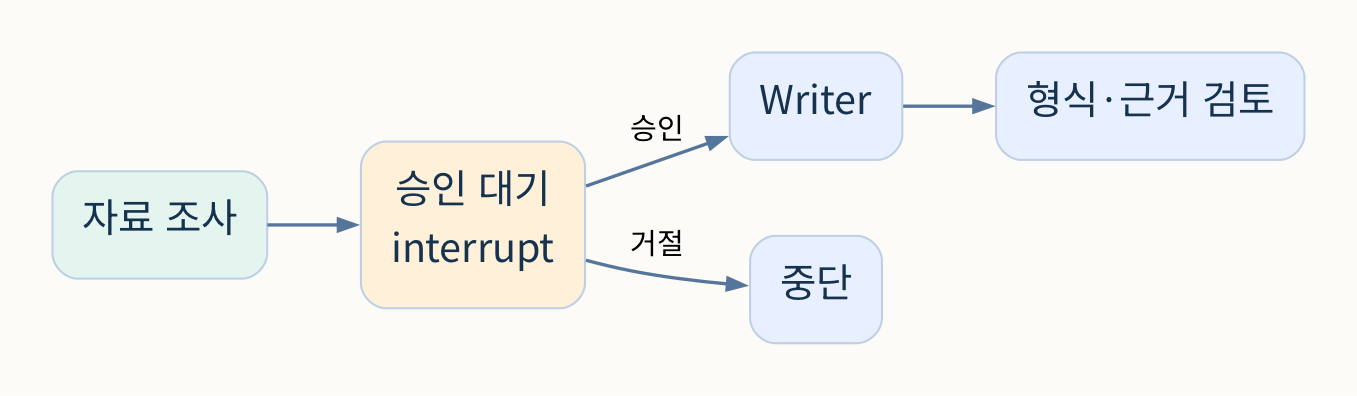

**그림 2.2.4.1 — 거절 경로는 Writer를 통과하지 않습니다**

사람이 근거를 본 뒤 승인해야 작성 노드로 이동합니다. 거절은 별도 종료 경로입니다.

**보면서 확인:** 승인 화면 문구와 코드의 분기가 서로 맞는지 찾아보세요.

**표현 범위:** 수업 예제는 외부 발송이 없으며 서비스별 승인 정책은 별도 설계가 필요합니다.


In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command
class ApprovalState(TypedDict, total=False):
    draft: str
    approved: bool
    sent: bool

def build_approval_demo():
    def approval(state):
        decision = interrupt({"draft": state["draft"], "question": "진행할까요?"})
        if type(decision) is not bool:
            raise ValueError("True 또는 False로 승인해 주세요.")
        return {"approved": decision}
    def execute(state):
        return {"sent": True}  # 외부 발송 없이 실행 여부만 표시
    graph = StateGraph(ApprovalState)
    graph.add_node("approval", approval)
    graph.add_node("execute", execute)
    graph.add_edge(START, "approval")
    graph.add_conditional_edges("approval", lambda s: "execute" if s["approved"] else END, ["execute", END])
    graph.add_edge("execute", END)
    return graph.compile(checkpointer=InMemorySaver())

approval_graph = build_approval_demo()
approval_config = {"configurable": {"thread_id": "approval-demo"}}
paused = approval_graph.invoke({"draft": "교육용 초안", "sent": False}, approval_config)
print("승인 대기:", bool(paused.get("__interrupt__")))
rejected = approval_graph.invoke(Command(resume=False), approval_config)
print("거절 뒤 실행 여부:", rejected["sent"])
assert rejected["sent"] is False


**실행에서 볼 것**

거절 상태에서는 execute 노드를 거치지 않습니다. “거절했습니다”라는 문구만 출력하는 코드와 실제 분기를 구분하세요.


**CodeMate와 확인하기**

> 승인·거절·잘못된 승인값을 각각 새로운 thread로 실행해 주세요. 거절 시 sent가 False인지 검증하고, interrupt 전에 부작용이 없는지 코드를 리뷰해 주세요.


### 2.2.5 분기를 바꿨으면 양쪽을 실행하기

그래프 코드는 정상 경로만 실행하면 결함을 놓치기 쉽습니다. 승인과 거절, 근거 있음과 없음, 성공과 오류처럼 분기의 양쪽을 확인합니다. 상태 저장을 사용하는 경우에는 매번 새로운 thread로 시작한 결과와 같은 thread로 이어간 결과를 구분해야 합니다.

CodeMate가 수정한 코드를 검토할 때 먼저 변경된 조건과 Edge를 읽습니다. 다음으로 입력을 바꾸어 각 경로를 실행합니다. 결과 문장이 자연스러운지만 보지 말고 실행되면 안 되는 노드가 호출됐는지도 확인하세요.

아래 두 실행은 서로 다른 그래프와 thread를 사용합니다. 앞 실습의 저장 상태가 다음 결과를 미리 결정하지 않도록 구성합니다.


In [ ]:
for decision in [True, False]:
    fresh_graph = build_approval_demo()
    config = {"configurable": {"thread_id": str(uuid.uuid4())}}
    fresh_graph.invoke({"draft": "교육용 초안", "sent": False}, config)
    final = fresh_graph.invoke(Command(resume=decision), config)
    assert final["sent"] is decision
    print("승인", decision, "→ 실행", final["sent"])


**실행에서 볼 것**

True일 때만 sent가 True가 됩니다. 동일한 DB나 thread를 재사용하는 시연에서 이전 결과가 섞일 가능성도 생각해 보세요.


**CodeMate와 확인하기**

> 근거 목록이 비어 있으면 승인 질문도 띄우지 않고 종료하도록 그래프를 확장해 주세요. 근거 없음·거절·승인의 세 경로에서 execute 실행 여부를 검증하고 변경된 Edge를 설명해 주세요.


## 2.3 역할 분리와 Streamlit

**이 블록의 결과물:** 조사·작성의 책임을 나누고 질문·답변·근거를 사용자 화면에 표시합니다.


### 2.3.1 언제 역할을 나눌까

단일 Agent에 조사·계획·작성·검토를 모두 맡기면 도구와 맥락이 많아져 현재 역할을 구분하기 어려울 수 있습니다. 역할을 나누면 각 단계의 입력, 사용할 도구, 산출물과 검토 기준을 줄일 수 있습니다.

역할이 늘면 호출 비용, 지연, 전달 오류도 늘어납니다. 짧은 질문에 답하는 작업은 단일 흐름으로 충분할 수 있습니다. 여러 Agent가 있다는 사실보다 **책임 경계가 명확한가**를 먼저 판단하세요.

보고서 예에서는 Researcher가 문서 ID와 근거를 반환하고 Writer는 받은 근거로 문장을 구성합니다. Writer가 모르는 자료를 추가 검색하거나 없는 출처를 만들어도 되는지는 계약에 명시해야 합니다.


In [ ]:
contracts = {
    "Researcher": {"input": "질문", "output": "문서 ID·본문·출처", "check": "질문 관련성"},
    "Writer": {"input": "선택된 근거", "output": "출처가 붙은 초안", "check": "근거 밖 주장 없음"},
}
for role, contract in contracts.items():
    print(role, contract)


**CodeMate와 확인하기**

> “숫자 두 개의 곱셈”과 “여러 자료를 비교한 보고서”를 각각 단일 흐름 또는 역할 분리로 설계해 주세요. 필요한 입력·산출물·검토 기준을 적고, Agent 수를 늘려서 생기는 비용도 설명해 주세요.


### 2.3.2 Researcher·Writer·Supervisor의 계약

Supervisor는 전체 목표와 다음 역할을 관리합니다. Hierarchical 구조에서는 하위 조정자가 일부 작업을 다시 나눕니다. Network 구조에서는 서로 직접 요청할 수 있지만 종료·충돌·전달 규칙이 더 중요해집니다.

아래는 Researcher→Writer 순서가 고정된 작은 Workflow입니다. 실제 LLM이 다음 역할을 선택하는 Supervisor와 구별하세요. 먼저 책임과 데이터 전달을 검증한 뒤 선택을 모델에 맡길지 결정합니다.

근거에는 원문과 출처를 함께 넣습니다. Writer가 전달받은 자료의 범위를 벗어나지 않는지 확인할 수 있어야 합니다. 4일차에는 두 역할 사이에 승인과 평가를 붙여 캡스톤을 완성합니다.


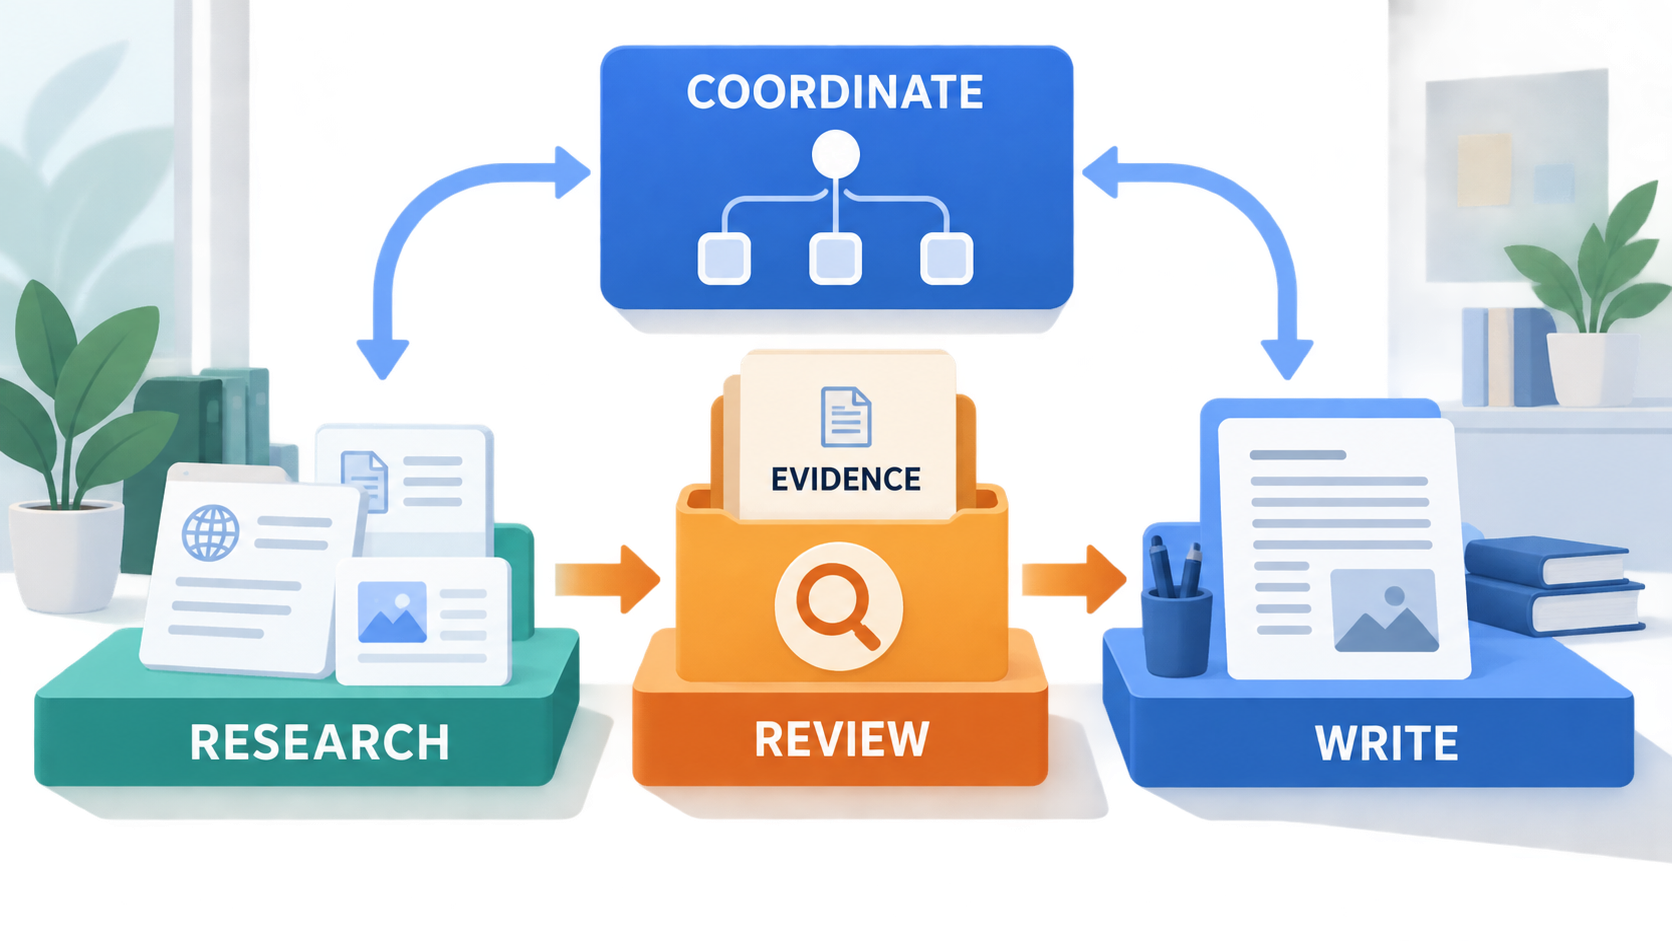

**그림 2.3.2.1 — 근거를 넘기는 경계에서 검토합니다**

조정자는 목표를 관리하고 Researcher는 자료를, Writer는 보고서를 만듭니다. 가운데 검토 단계는 근거가 다음 역할로 넘어가기 전에 확인할 지점입니다.

**보면서 확인:** Writer에게 자료 전체와 선택된 근거 중 무엇을 넘길지 결정해 보세요.

**표현 범위:** 역할별 실제 LLM 호출 수나 병렬 실행 순서를 나타내는 정확한 실행도는 아닙니다.


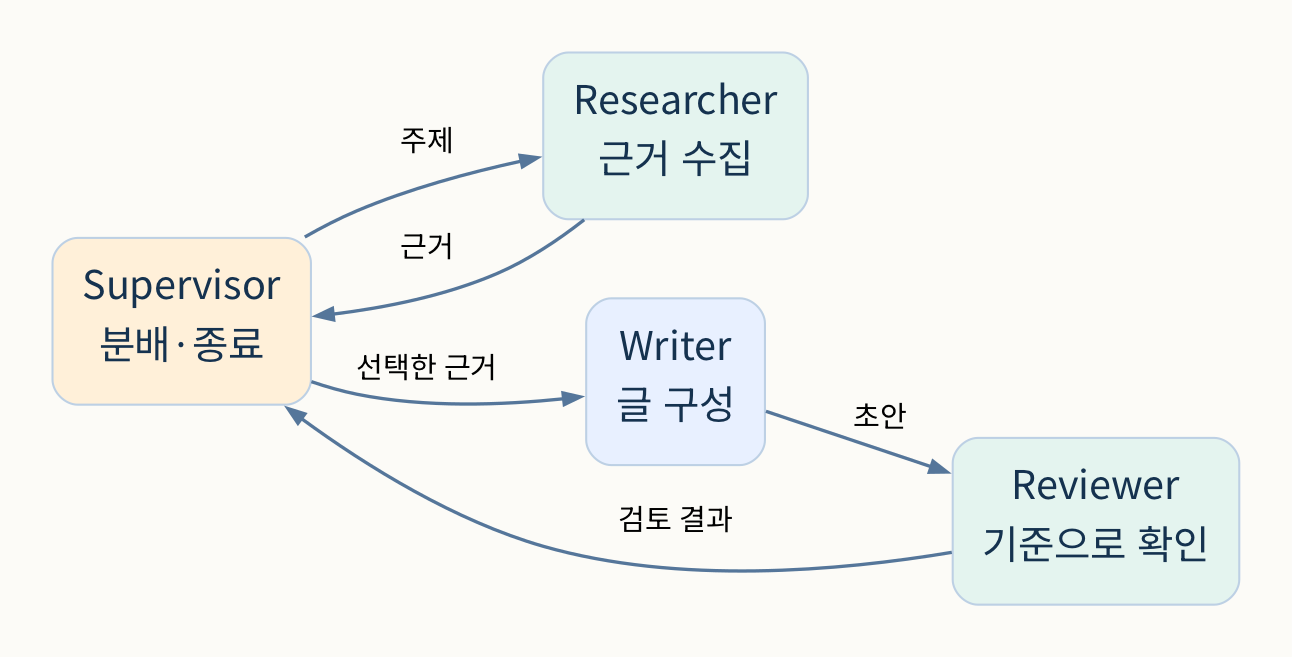

**그림 2.3.2.2 — 역할 사이의 입출력 계약**

Researcher의 자료를 Writer가 받아 작성하며, 조정 역할이 다음 작업을 관리합니다.

**보면서 확인:** 각 역할이 어떤 결과를 다음 역할에 넘기는지 확인하세요.

**표현 범위:** 이 구간은 고정 Workflow로 두 역할의 계약을 실행합니다. 상태 기반 Supervisor는 4.3에서 구현합니다.


In [ ]:
class TeamState(TypedDict, total=False):
    topic: str
    evidence: list[dict]
    report: str

def researcher(state):
    return {"evidence": retrieve(state["topic"], k=2)}
def writer(state):
    return {"report": "\n".join(f'{d["text"]} [{d["id"]}]' for d in state["evidence"]) or "근거가 없습니다."}
team = StateGraph(TeamState)
team.add_node("researcher", researcher)
team.add_node("writer", writer)
team.add_edge(START, "researcher")
team.add_edge("researcher", "writer")
team.add_edge("writer", END)
team_graph = team.compile()
team_result = team_graph.invoke({"topic": "RAG 검색 근거"})
print(team_result["report"])


**실행에서 볼 것**

Writer가 임의 정보를 생성하지 않고 원문을 발췌합니다. 흐름 검증과 LLM의 글쓰기 품질 평가는 다릅니다.


**CodeMate와 확인하기**

> Researcher의 반환값에서 source를 지우면 무엇이 불편해지는지 설명해 주세요. Writer가 근거 ID를 보존하도록 계약 검사를 추가하고, 빈 근거일 때 작성 노드를 건너뛰도록 분기해 주세요.


### 2.3.3 Streamlit의 재실행과 세션 상태

Streamlit은 위젯 입력이 바뀌면 스크립트를 다시 실행합니다. 일반 변수에 대화 기록을 넣으면 재실행 때 초기화될 수 있으므로 `st.session_state`에 보관합니다. 화면 표시와 모델 호출을 같은 위치에 두면 과거 메시지를 다시 그릴 때 API를 중복 호출할 수 있습니다.

이 실습 앱은 입력이 들어온 경우에만 자료를 검색하고, 이전 메시지는 저장된 결과로 다시 표시합니다. 답변 아래에서 사용한 근거를 펼쳐 볼 수 있습니다. 기본값은 교육용 문서의 원문 발췌이며 외부 API를 호출하지 않습니다.

프로젝트 루트 터미널에서 다음 명령으로 화면을 엽니다.

```bash
uv run --extra notebooks streamlit run src/courseware/app.py
```

노트북에서는 서버를 계속 켜는 대신 공식 AppTest로 입력 후 화면과 세션 결과를 확인합니다. 이는 실제 브라우저의 글꼴·배치 검증을 대신하지는 않습니다.


In [ ]:
from streamlit.testing.v1 import AppTest
ui = AppTest.from_file(str(ROOT / "src/courseware/app.py"), default_timeout=20).run()
assert not ui.exception
ui.chat_input[0].set_value("RAG 검색 근거").run()
assert not ui.exception
print("대화 메시지 수:", len(ui.session_state["messages"]))
print("마지막 답변:", ui.session_state["messages"][-1]["content"])


**실행에서 볼 것**

사용자 질문과 답변이 세션에 각각 한 번 추가됩니다. 근거 출처가 없는 질문도 화면에서 확인해 보세요.


**CodeMate와 확인하기**

> src/courseware/app.py를 읽고 입력 처리, 이전 메시지 표시, 자료 검색 위치를 찾아 주세요. 새로고침과 위젯 재실행에서 대화가 어떻게 달라지는지 설명하고, 답변을 다시 그릴 때 검색을 중복 실행하지 않는지 확인해 주세요.


### 2.3.4 질문·답변·근거를 한 화면으로 연결하기

사용자가 답변만 보면 자료에 없는 내용을 알아차리기 어렵습니다. 질문, 답변, 사용한 근거를 같은 흐름에서 확인할 수 있게 구성합니다. 근거 없음은 빈 화면이나 오류 대신 명확한 안내로 보여 줍니다.

화면이 그럴듯해도 검색이 잘못되면 결과는 틀릴 수 있습니다. UI 검토에서는 입력이 제대로 전달됐는지, 답변에 출처가 있는지, 근거 없음이 구별되는지, 이전 대화가 남는지를 확인합니다. 검색 로직의 품질은 별도 질의셋으로 검토합니다.

CodeMate에는 화면 요소와 데이터 계약을 함께 전달하세요. 버튼을 추가할 때는 그 버튼이 실제 사용자의 어떤 판단을 돕는지 설명할 수 있어야 합니다.


In [ ]:
ui.chat_input[0].set_value("교육장 휴게실 위치").run()
assert not ui.exception
assert ui.session_state["messages"][-1]["content"] == "문서에서 확인할 수 없습니다."
assert len(ui.session_state["messages"]) == 4
print("두 질문의 대화가 보존되고, 근거 없음 안내가 표시됩니다.")


**CodeMate와 확인하기**

> 앱에 검색 결과 수를 선택하는 기능을 추가하려면 UI와 검색 함수 어디를 고쳐야 하는지 먼저 계획해 주세요. 허용 범위 1~5, 빈 질문, 근거 없음, 대화 보존을 검증 기준으로 쓰세요. 실제 사내 문서를 사용하지 말고 교육용 문서만 사용하세요.


### 2.3.5 하나의 실행을 끝까지 설명하기

오늘의 완성 경로는 질문→검색→근거→상태 갱신→승인 또는 중단→답변·화면입니다. 모든 실습을 하나의 거대한 파일로 합치기 전에 각 연결의 입력과 출력을 설명할 수 있어야 합니다.

검토할 때는 실패를 한 단계에 연결합니다. 문서를 못 찾았으면 검색, 근거에 없는 말을 했으면 생성·검토, 거절해도 실행했다면 분기, 대화가 사라졌으면 상태·세션을 확인합니다. 같은 오류 메시지라도 원인은 다를 수 있습니다.

다음 날에는 같은 검색 기능을 MCP 서버로 제공하고 다른 Agent에 A2A로 작업을 위임합니다. 오늘 정한 입력·출력 계약이 프로세스 밖으로 이동해도 유지되는지 확인할 것입니다.


In [ ]:
checks = {
    "근거 없는 질문": answer_from_documents("교육장 휴게실 위치")["sources"] == [],
    "거절하면 실행 안 함": rejected["sent"] is False,
    "UI 대화 보존": len(ui.session_state["messages"]) == 4,
}
print(checks)
assert all(checks.values())


**CodeMate와 확인하기**

**완료 기준:** 검색 실패·승인 거절·세션 보존을 각각 한 번 보여 주고 원인과 결과를 설명합니다.

> 오늘 코드에서 가장 바꾸고 싶은 한 가지를 고르고, 변경 목표·수정 범위·정상 사례·실패 사례를 적어 주세요. CodeMate의 제안을 적용하기 전 영향받는 State 필드와 화면을 확인하세요.


**원본 연결:** [RAG PDF](../docs/raw/Chapter01/day01/1-4-rag-theory-and-core-modules.pdf), [LangGraph PDF](../docs/raw/Chapter01/day02/2-1-langgraph-theory-and-advanced-features.pdf), [Multi-Agent PDF](../docs/raw/Chapter01/day02/2-2-multi-agent-collaboration-introduction.pdf), [Streamlit PDF](../docs/raw/Chapter01/day02/2-3-streamlit-rag.pdf). 실습은 `src/raw/Chapter01/03-rag/`부터 `06-rag-streamlit/`까지입니다. 통합본의 승인 예제는 외부 발송 없는 별도 예제로 재구성했습니다.
